# PINN 2D · 带孔板线弹性

主线二覆盖二维固体。$2\,\mathrm{m}\times2\,\mathrm{m}$ 平面应力板中心有半径
$0.25\,\mathrm{m}$ 的圆孔；左边固定，右边施加 $1\,\mathrm{MPa}$ 拉力，其余外边与
孔边无牵引。网络输出 $(u_x,u_y)$，动量平衡、位移和牵引条件共同进入 loss。

下面复用仓库 ProblemSpec/MethodSpec，执行固定种子的 10 步 CPU **smoke**。Kirsch
解假设无限板，这里只作为物理量级与应力集中系数参考，不是有限板精度声明。

In [1]:
from pathlib import Path
import csv
import json
import math
import sys

import numpy as np
import torch
from IPython.display import HTML, SVG, display

import openpinn as op

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from examples.tutorials._viz import comparison_svg, field_svg, loss_svg

print("OpenPINN", op.__version__, "| CPU smoke | repo", ROOT.name)


OpenPINN 0.2.0 | CPU smoke | repo OpenPINN-upstream


## 从规格构建并训练

In [2]:
from examples.plate_with_hole import run

summary = run(
    smoke=True, device="cpu",
    output_dir=Path("/tmp/openpinn-m18-pinn-plate-with-hole"),
)
print(json.dumps({key: summary[key] for key in (
    "steps", "status", "final_total_loss", "pde_residual_rmse", "kirsch_scf_value"
)}, indent=2))

step=1 total=9.088931e+22
step=2 total=7.647036e+22
step=3 total=8.867173e+22
step=4 total=8.832367e+22
step=5 total=9.695438e+22
step=6 total=7.965303e+22
step=7 total=8.055105e+22
step=8 total=9.805918e+22
step=9 total=1.136327e+23
step=10 total=9.463639e+22
{
  "steps": 10,
  "status": "completed_with_finite_outputs",
  "final_total_loss": 9.463639076974992e+22,
  "pde_residual_rmse": 27307687936.0,
  "kirsch_scf_value": 3.0
}


## 训练损失

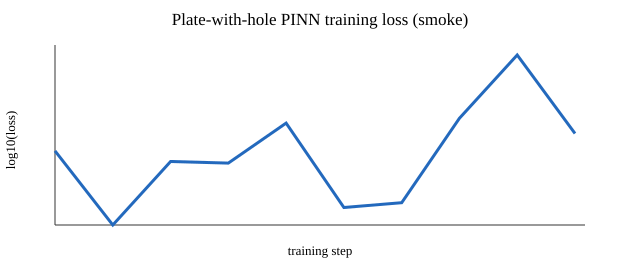

In [3]:
output_dir = Path(summary["output_dir"])
with (output_dir / "history.csv").open(encoding="utf-8-sig") as stream:
    history = list(csv.DictReader(stream))
losses = [float(row["total"]) for row in history]
display(SVG(data=loss_svg(losses, "Plate-with-hole PINN training loss (smoke)")))

## 位移场与圆孔几何

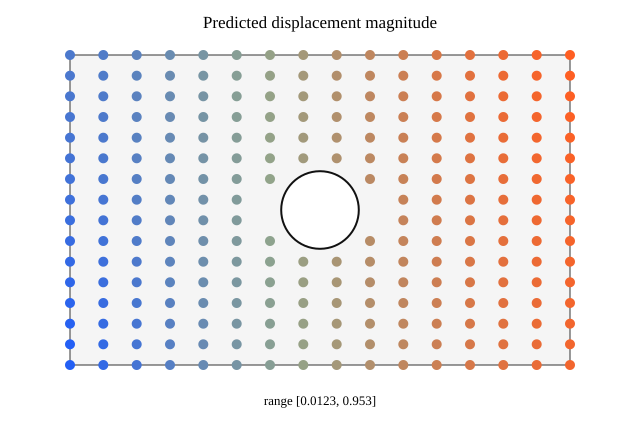

Kirsch SCF reference: 3.0 | finite plate smoke, not accuracy


In [4]:
saved = np.load(output_dir / "predictions.npz")
displacement = np.linalg.norm(saved["prediction"], axis=1)
display(SVG(data=field_svg(
    saved["coordinates"], displacement, "Predicted displacement magnitude",
    hole_radius=0.25, hole_center=(1.0, 1.0),
)))
print("Kirsch SCF reference:", summary["kirsch_scf_value"], "| finite plate smoke, not accuracy")